In [82]:
# import the librarires

In [299]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [300]:
# ------read the data---------
df=pd.read_csv('Netflix (1).csv')
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

  date_added  release_year rating   duration  \
0  25-Sep-21          2020  PG-13     90 min   
1  24-Sep-21          2021  TV-MA  2 Seasons   
2  24-Sep-21          2021  TV-MA   1 Season   
3  24-Se

In [301]:
# ---understand the data------
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe(include="all"))

(200, 12)
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       200 non-null    str  
 1   type          200 non-null    str  
 2   title         200 non-null    str  
 3   director      137 non-null    str  
 4   cast          180 non-null    str  
 5   country       136 non-null    str  
 6   date_added    200 non-null    str  
 7   release_year  200 non-null    int64
 8   rating        200 non-null    str  
 9   duration      200 non-null    str  
 10  listed_in     200 non-null    str  
 11  description   200 non-null    str  
dtypes: int64(1), str(11)
memory usage: 18.9 KB
None
       show_id   type                 title           director  \
count      200    200         

In [302]:
# lets find the miising values
print(df.isnull().sum())

show_id          0
type             0
title            0
director        63
cast            20
country         64
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [303]:
# cleanning the missing values
# droping 2 colmns because these 2 are no longer use in EDA
df.head()
df=df.drop(columns=['director','cast'])


In [304]:
# check again for missing values
print(df.isnull().sum())

show_id          0
type             0
title            0
country         64
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [305]:
# handling missing values in country column with replacing with mode because its categorical column
# print(df['country'])
mode_value=df["country"].mode()[0]
df["country"]=df['country'].fillna(mode_value)
print(df["country"].isnull().sum())
print(df.isnull().sum())

0
show_id         0
type            0
title           0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [306]:
# ----------checking duplicate values in dataframe--------------
df1=df.duplicated().sum()
print(df1)
df.head()

0


,show_id,type,title,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,United States,25-Sep-21,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,South Africa,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,United States,24-Sep-21,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,United States,24-Sep-21,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,India,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### starting transformation for those column who will used in business objective
### ------------------------------------which are more no. of shows or movie on netflix?-------------------------------------


type
Movie      127
TV Show     73
Name: count, dtype: int64


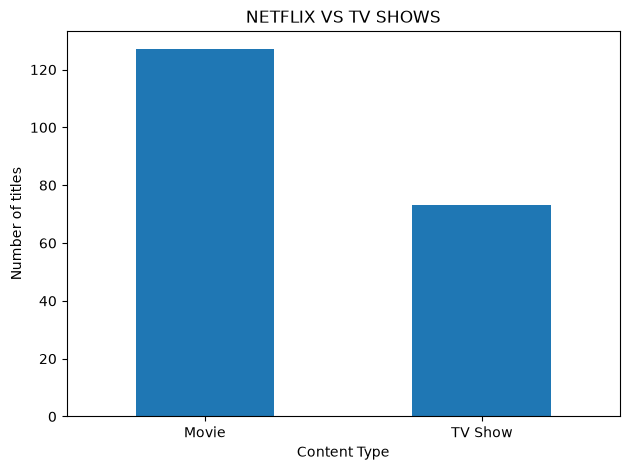

In [307]:
type_counts=df["type"].value_counts()
print(type_counts)


# -------------------------create graph--------------
type_counts.plot(kind="bar")
plt.title("NETFLIX VS TV SHOWS")
plt.xlabel("Content Type")
plt.ylabel("Number of titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### ------------------------------------which country has more content ---------------------------


In [308]:
df['country']=df['country'].str.strip()
df["country"]=df["country"].str.split(",")
df_country=df.explode("country")
df_country["country"]=df_country["country"].str.strip()

In [309]:
country_counts=df_country["country"].value_counts()
high_conten_country=country_counts.head(10)

### -----------which countries have more content ----------------

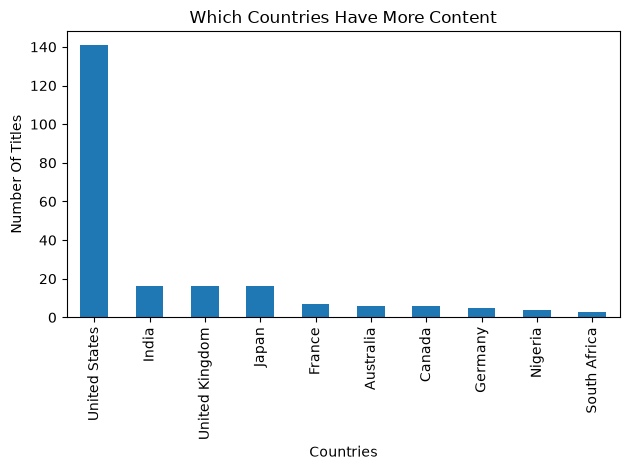

In [310]:
high_conten_country.plot(kind="bar")
plt.title("Which Countries Have More Content")
plt.xlabel("Countries")
plt.ylabel("Number Of Titles")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### --------------------------In which year has more content added-----------------------

In [311]:
# df.head()
df["date_added"]=pd.to_datetime(df["date_added"].str.strip(),format="%d-%b-%y",errors="coerce")
df["year_added"]=df["date_added"].dt.year
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       200 non-null    str           
 1   type          200 non-null    str           
 2   title         200 non-null    str           
 3   country       200 non-null    object        
 4   date_added    200 non-null    datetime64[us]
 5   release_year  200 non-null    int64         
 6   rating        200 non-null    str           
 7   duration      200 non-null    str           
 8   listed_in     200 non-null    str           
 9   description   200 non-null    str           
 10  year_added    200 non-null    int32         
dtypes: datetime64[us](1), int32(1), int64(1), object(1), str(7)
memory usage: 16.5+ KB


year_added
2021    200
Name: count, dtype: int64
2021
200


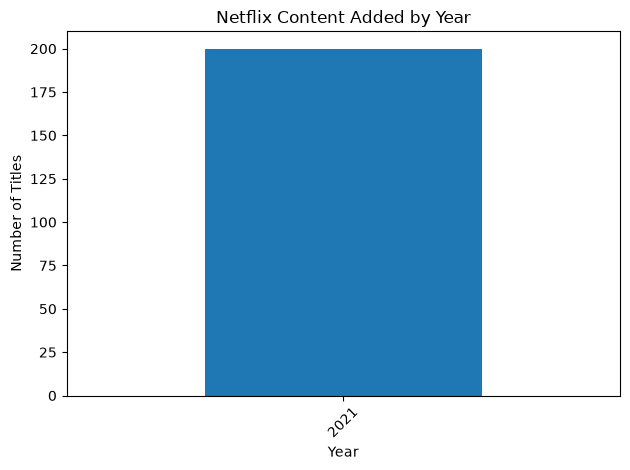

In [312]:
most_content_added_year=df["year_added"].value_counts().sort_index()
print(most_content_added_year)
print(most_content_added_year.idxmax())
print(most_content_added_year.max())


most_content_added_year.plot(kind="bar")
plt.title("Netflix Content Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### -----------------Top 10 genres on netflix--------------------------------------

In [315]:
df["listed_in"]=df["listed_in"].str.strip()
df["listed_in"]=df["listed_in"].str.split(",")
df_genre=df.explode("listed_in")
df_genre["listed_in"]=df_genre["listed_in"].str.strip()

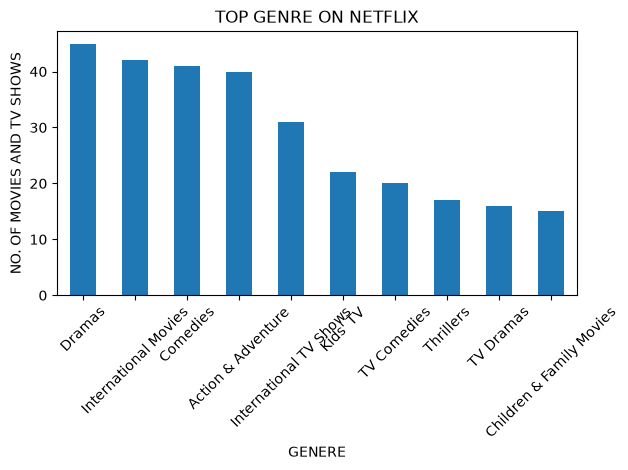

In [322]:
top_genre=df_genre["listed_in"].value_counts()
top_10_genre_counts=top_genre.head(10)
# print(top_10_genre_counts)

top_10_genre_counts.plot(kind="bar")
plt.title("TOP GENRE ON NETFLIX")
plt.xlabel("GENERE")
plt.ylabel("NO. OF MOVIES AND TV SHOWS")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### -------------What is the distribution of movie durations and the number of seasons in TV shows on Netflix? -------


In [342]:
df.head()
movies_df=df[df["type"]=="Movie"]
tv_shows_df=df[df["type"]=="TV Show"]
movies_df.head()


,show_id,type,title,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,[United States],2021-09-25,2020,PG-13,90 min,[Documentaries],"As her father nears the end of his life, filmm...",2021
6,s7,Movie,My Little Pony: A New Generation,[United States],2021-09-24,2021,PG,91 min,[Children & Family Movies],Equestria's divided. But a bright-eyed hero be...,2021
7,s8,Movie,Sankofa,"[United States, Ghana, Burkina Faso, United...",2021-09-24,1993,TV-MA,125 min,"[Dramas, Independent Movies, International M...","On a photo shoot in Ghana, an American model s...",2021
9,s10,Movie,The Starling,[United States],2021-09-24,2021,PG-13,104 min,"[Comedies, Dramas]",A woman adjusting to life after a loss contend...,2021
12,s13,Movie,Je Suis Karl,"[Germany, Czech Republic]",2021-09-23,2021,TV-MA,127 min,"[Dramas, International Movies]",After most of her family is murdered in a terr...,2021


In [343]:
tv_shows_df.head()

,show_id,type,title,country,date_added,release_year,rating,duration,listed_in,description,year_added
1,s2,TV Show,Blood & Water,[South Africa],2021-09-24,2021,TV-MA,2 Seasons,"[International TV Shows, TV Dramas, TV Myste...","After crossing paths at a party, a Cape Town t...",2021
2,s3,TV Show,Ganglands,[United States],2021-09-24,2021,TV-MA,1 Season,"[Crime TV Shows, International TV Shows, TV ...",To protect his family from a powerful drug lor...,2021
3,s4,TV Show,Jailbirds New Orleans,[United States],2021-09-24,2021,TV-MA,1 Season,"[Docuseries, Reality TV]","Feuds, flirtations and toilet talk go down amo...",2021
4,s5,TV Show,Kota Factory,[India],2021-09-24,2021,TV-MA,2 Seasons,"[International TV Shows, Romantic TV Shows, ...",In a city of coaching centers known to train I...,2021
5,s6,TV Show,Midnight Mass,[United States],2021-09-24,2021,TV-MA,1 Season,"[TV Dramas, TV Horror, TV Mysteries]",The arrival of a charismatic young priest brin...,2021


In [344]:
movie_distribution_count=movies_df["duration"].value_counts()
print(movie_distribution_count)

duration
95 min     7
94 min     5
97 min     5
106 min    5
91 min     4
          ..
89 min     1
156 min    1
112 min    1
129 min    1
135 min    1
Name: count, Length: 64, dtype: int64


In [348]:
tv_shows_distribution_count=tv_shows_df["duration"].value_counts()
print(tv_shows_distribution_count)

duration
1 Season     43
2 Seasons    13
3 Seasons     5
5 Seasons     4
4 Seasons     3
6 Seasons     3
9 Seasons     2
Name: count, dtype: int64


### ----------------visualization of movie distribution and tv shows distribution--------------

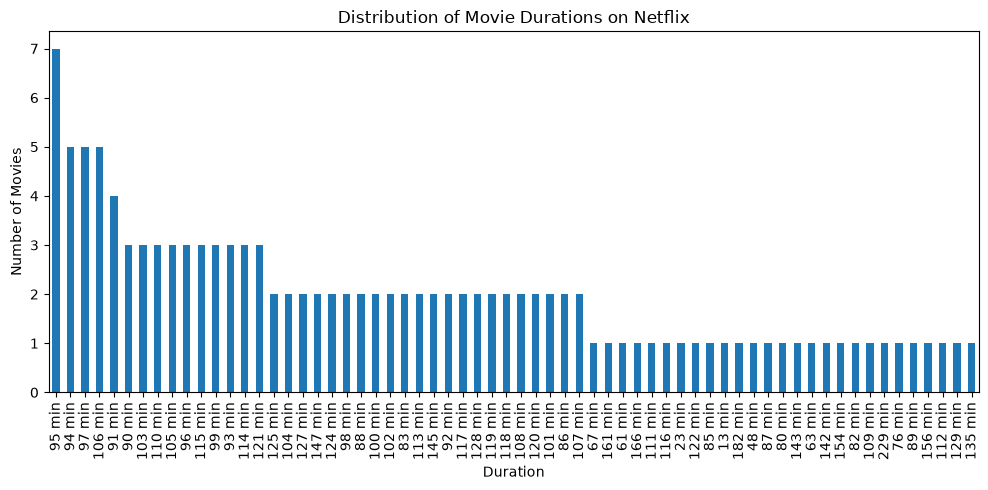

In [347]:
movie_distribution_count.plot(kind="bar", figsize=(10, 5))

plt.title("Distribution of Movie Durations on Netflix")
plt.xlabel("Duration")
plt.ylabel("Number of Movies")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

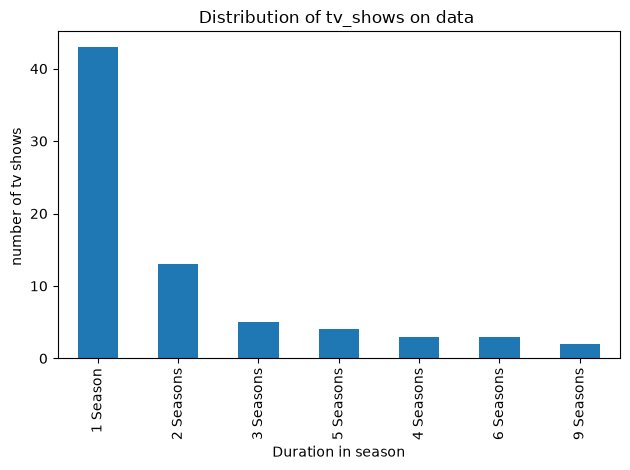

In [351]:
tv_shows_distribution_count.plot(kind="bar")

plt.title("Distribution of tv_shows on data ")
plt.xlabel("Duration in season")
plt.ylabel("number of tv shows ")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()